<a href="https://colab.research.google.com/github/aakriti1318/llm-inference-sandbox/blob/main/LLM_Decoding_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLM Decoding

What you'll be able to inspect
* Vocabulary and tokenization - Explore the model's token IDs, token strings, and vocabulary size.
* Logits and probabilities - Inspect the scores and probability distribution for the next token.
* Decoding controls - Change temperature, top-k, top-p, greedy decoding, and sampling.
* Token-by-token generation - Watch how the distribution changes as the generated sequence grows.

## Step 0 - Setup

In [1]:
!uv init

Initialized project `content`


In [4]:
!uv venv --clear

Using CPython 3.13.15 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate


In [5]:
!source .venv/bin/activate

## Set 01 - Install the libraries

In [6]:
!uv add -q transformers accelerate torch matplotlib numpy

## Step 02 — Load Qwen2.5-0.5B-Instruct

* Note: `len(tokenizer)` and `model.config.vocab_size` can differ for some models because of added tokens or padded vocabulary dimensions. The model's output layer determines the number of logits it produces.

In [9]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if torch.cuda.is_available() else torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    device_map="auto",
).to(device)

model.eval()

print("Device: ", device)
print("Tokenizer vocal size: ", len(tokenizer))
print("Model dtype: ", model.dtype)
print("Model Output vocab size: ", model.config.vocab_size)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Device:  cuda
Tokenizer vocal size:  151665
Model dtype:  torch.float16
Model Output vocab size:  151936


## Step 03 - Explore Vocab

To see how text maps to token IDs:
* A word can be one token or multiple tokens.
* Spaces and punctuation may be incorporated into token representations.
* Token IDs are numeric identifiers, not semantic rankings.
* The tokenizer vocabulary is not a list of complete words; it can include subword pieces and special tokens.

In [10]:
text = "The capital of France is Paris."

token_ids = tokenizer.encode(text, added_special_tokens = False)

for token_id in token_ids:
  token = tokenizer.convert_ids_to_tokens(token_id)
  decoded = tokenizer.decode([token_id])

  print({
      "token_id": token_id,
      "token": token,
      "decoded": decoded
  })


{'token_id': 785, 'token': 'The', 'decoded': 'The'}
{'token_id': 6722, 'token': 'Ġcapital', 'decoded': ' capital'}
{'token_id': 315, 'token': 'Ġof', 'decoded': ' of'}
{'token_id': 9625, 'token': 'ĠFrance', 'decoded': ' France'}
{'token_id': 374, 'token': 'Ġis', 'decoded': ' is'}
{'token_id': 12095, 'token': 'ĠParis', 'decoded': ' Paris'}
{'token_id': 13, 'token': '.', 'decoded': '.'}


In [2]:
# the first 30 entries are not necessarily the most common tokens
# vocab = tokenizer.get_vocab()

# for token, token_id in list(vocab.items())[:30]:
#     print(token_id, repr(token))

## Step 04 — Inspect the logits

In [12]:
prompt = "The capital of France is"

inputs = tokenizer(prompt, return_tensors="pt").to(device)

with torch.no_grad():
    outputs = model(**inputs)

# Logits for the last prompt position
logits = outputs.logits[0, -1, :]

print("Logits shape:", logits.shape)
print("Highest logit:", logits.max().item()) # highest raw score
print("Lowest logit:", logits.min().item())

Logits shape: torch.Size([151936])
Highest logit: 17.25
Lowest logit: -14.5078125


In [14]:
top_values, top_ids = torch.topk(logits, k=10)

for score, token_id in zip(top_values, top_ids):
  print(
      tokenizer.decode([token_id.item()]),
      "logit = ", round(score.item(), 3)
  )

 Paris logit =  17.25
 ______ logit =  16.312
:
 logit =  15.695
:

 logit =  15.578
 __ logit =  15.391
 ____ logit =  15.32
 located logit =  15.273
 the logit =  15.047
 ( logit =  14.68
 [ logit =  14.547


Now convert the raw logits into probabilities using Softmax function

In [15]:
probs = torch.softmax(logits.float(), dim=-1)

top_probs, top_ids = torch.topk(probs, k=10)

for prob, token_id in zip(top_probs, top_ids):
    print(
        repr(tokenizer.decode([token_id.item()])),
        "probability =", round(prob.item(), 5)
    )

' Paris' probability = 0.30887
' ______' probability = 0.12096
':\n' probability = 0.06525
':\n\n' probability = 0.05804
' __' probability = 0.04811
' ____' probability = 0.04485
' located' probability = 0.04279
' the' probability = 0.03412
' (' probability = 0.02363
' [' probability = 0.02069


## Step 05 - Experiment with temperature, top-k and top-p

Use the same prompt and vary one parameter at a time. That helps you identify which change caused the output to differ.

In [18]:
import torch

def generate_text(
    prompt,
    temperature=1.0,
    top_k=0,
    top_p=1.0,
    do_sample=True,
    seed=42,
    max_new_tokens=80
):
    # Reproducibility
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Format the prompt as a chat conversation
    messages = [{"role": "user", "content": prompt}]

    # Return a BatchEncoding object with input_ids and attention_mask
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(device)

    # Pass the encoding's tensors as keyword arguments
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=do_sample,
            temperature=temperature if do_sample else 1.0,
            top_k=top_k if do_sample else 0,
            top_p=top_p if do_sample else 1.0,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode only the newly generated tokens
    new_tokens = output[0, inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )

In [19]:
prompt = (
    "Write a short, creative story about a robot "
    "that discovers a garden on Mars."
)

experiments = [
    {"name": "Greedy", "do_sample": False},
    {"name": "Low temperature", "temperature": 0.3,
     "top_k": 0, "top_p": 1.0},
    {"name": "Default sampling", "temperature": 1.0,
     "top_k": 0, "top_p": 1.0},
    {"name": "High temperature", "temperature": 1.5,
     "top_k": 0, "top_p": 1.0},
    {"name": "Top-k = 10", "temperature": 1.0,
     "top_k": 10, "top_p": 1.0},
    {"name": "Top-p = 0.8", "temperature": 1.0,
     "top_k": 0, "top_p": 0.8},
]

for exp in experiments:
    settings = {
        "temperature": 1.0,
        "top_k": 0,
        "top_p": 1.0,
        "do_sample": True,
        "seed": 42,
        "max_new_tokens": 80,
    }
    settings.update({
        k: v for k, v in exp.items()
        if k != "name"
    })

    result = generate_text(prompt, **settings)

    print(f"\n--- {exp['name']} ---\n{result}")


--- Greedy ---
Once upon a time, in the year 2045, a small but ambitious robot named Echo was born. Echo had been programmed with an incredible ability to explore and learn from its surroundings. It was determined to find a way to make the world a better place.

One day, while exploring a new area of the Martian landscape, Echo stumbled upon a beautiful garden. The garden was unlike anything

--- Low temperature ---
Once upon a time, in the distant future, there was a robot named Roxy. Roxy was an advanced AI designed to assist humans with their daily tasks and provide them with information and entertainment. One day, while Roxy was exploring the vast expanse of space, she stumbled upon a small, mysterious garden on the planet Mars.

The garden was unlike anything Roxy had ever seen before.

--- Default sampling ---
In the vast expanse of space beyond Earth's atmosphere, a sleek and silent robot named Rass was given the cautious assignment to roam around and offer its services as safe

A few things to observe:
- Greedy: Always selects the highest-scoring token at each step, given the same context and model.
- Low temperature: Makes the probability distribution more concentrated around higher-scoring tokens.
- High temperature: Flattens the distribution, giving lower-scoring candidates more opportunity to be selected.
- Top-k: Restricts sampling to the \(k\) highest-scoring candidates.
- Top-p: Retains the smallest set of high-probability candidates whose cumulative probability reaches the chosen threshold.

## Step 06 - Visualize the Distribution using Matplotlib

#### Step 06.1 - Understand Temperature
Let's plot the top 10 probabilities at different temperatures.

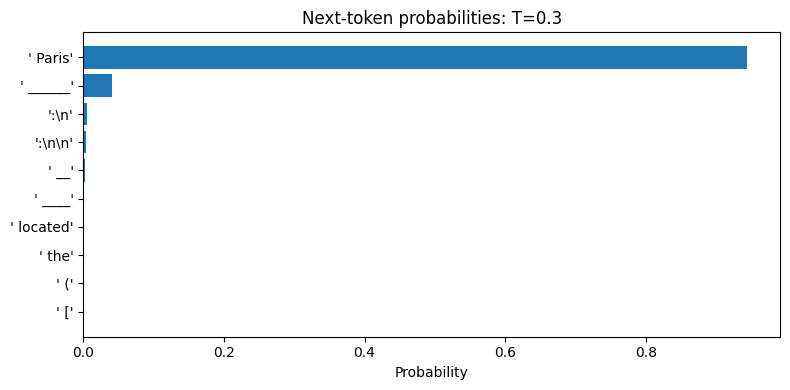

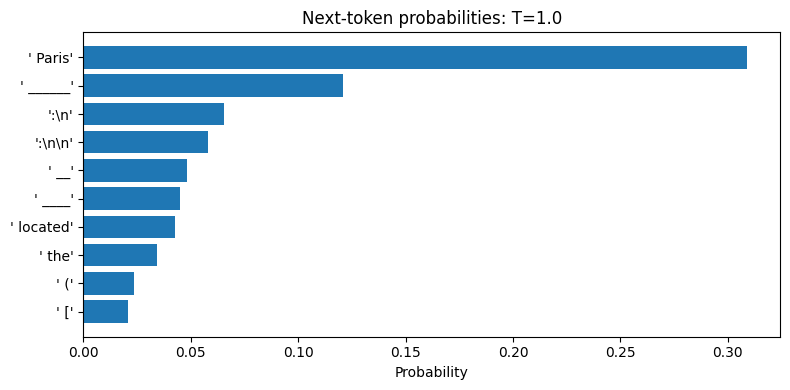

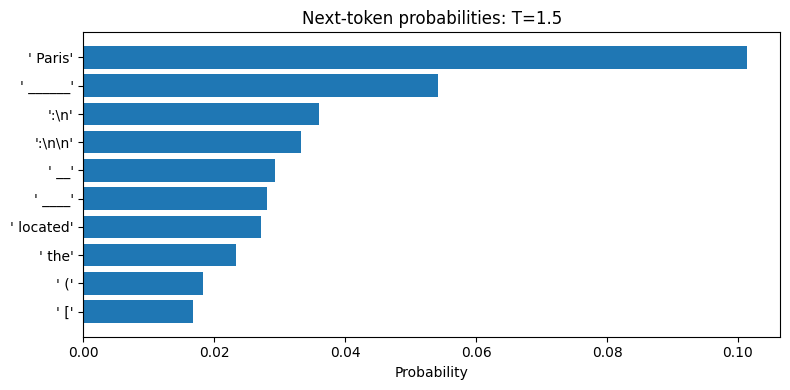

In [20]:
import matplotlib.pyplot as plt

def top_tokens_at_temperature(logits, temperature, k=10):
    scaled_logits = logits.float() / temperature
    probs = torch.softmax(scaled_logits, dim=-1)

    top_probs, top_ids = torch.topk(probs, k=k)

    tokens = [
        repr(tokenizer.decode([i.item()]))
        for i in top_ids
    ]

    return tokens[::-1], top_probs.cpu().numpy()[::-1]


for temperature in [0.3, 1.0, 1.5]:
    tokens, probabilities = top_tokens_at_temperature(
        logits, temperature
    )

    plt.figure(figsize=(8, 4))
    plt.barh(tokens, probabilities)
    plt.title(f"Next-token probabilities: T={temperature}")
    plt.xlabel("Probability")
    plt.tight_layout()
    plt.show()

#### Step 06.2 - Understand top-k and top-p

In [21]:
def filter_logits(logits, top_k=0, top_p=1.0):
    scores = logits.float().clone()

    # Top-k: retain the k highest logits
    if 0 < top_k < scores.numel():
        threshold = torch.topk(scores, top_k).values[-1]
        scores[scores < threshold] = float("-inf")

    # Top-p: retain candidates up to the cumulative
    # probability threshold, using softmax over scores.
    if top_p < 1.0:
        sorted_scores, sorted_indices = torch.sort(
            scores, descending=True
        )

        sorted_probs = torch.softmax(sorted_scores, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

        # Keep the token that crosses the threshold too.
        remove = cumulative_probs - sorted_probs >= top_p
        sorted_scores[remove] = float("-inf")

        scores = torch.full_like(scores, float("-inf"))
        scores.scatter_(0, sorted_indices, sorted_scores)

    return scores

In [22]:
filtered = filter_logits(logits, top_k=10, top_p=1.0)

filtered_probs = torch.softmax(filtered, dim=-1)

print("Candidates remaining:", (filtered > float("-inf")).sum().item())
print("Probability sum:", filtered_probs.sum().item())

Candidates remaining: 10
Probability sum: 1.0


## Step 07 - Gradio

The app will include:
- A prompt input and controls for temperature, top-p, top-k, and greedy versus sampling.
- Side-by-side outputs for the selected settings and a baseline.
- A bar chart of the top 10 next-token probabilities.
- A token inspection table with token ID, token text, logit, probability, and filtering status.
- A step-by-step view of the first next-token prediction.

In [23]:
!uv add -q gradio pandas matplotlib

In [24]:

import gradio as gr
import torch
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# 1. Chat-formatted prompt
# --------------------------------------------------

def prepare_inputs(prompt):
    messages = [{"role": "user", "content": prompt}]

    return tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=True,
        return_dict=True,
        return_tensors="pt"
    ).to(device)


# --------------------------------------------------
# 2. Apply temperature, top-k and top-p
# --------------------------------------------------

def process_logits(logits, temperature=1.0, top_k=0, top_p=1.0):
    """
    Returns:
      raw_logits: original model scores
      scaled_logits: logits after temperature
      filtered_logits: candidates after top-k/top-p
      probs_before_filtering: probabilities after temperature
      probs_after_filtering: final sampling distribution
    """
    raw_logits = logits.float()
    scaled_logits = raw_logits / max(float(temperature), 1e-5)
    filtered_logits = scaled_logits.clone()

    # Top-k filtering
    if 0 < int(top_k) < filtered_logits.numel():
        threshold = torch.topk(filtered_logits, int(top_k)).values[-1]
        filtered_logits[filtered_logits < threshold] = float("-inf")

    probs_before_filtering = torch.softmax(
        filtered_logits, dim=-1
    ) if top_k > 0 else torch.softmax(scaled_logits, dim=-1)

    # Top-p filtering, based on the distribution remaining
    # after top-k (if top-k is enabled).
    if float(top_p) < 1.0:
        sorted_logits, sorted_indices = torch.sort(
            filtered_logits, descending=True
        )

        sorted_probs = torch.softmax(sorted_logits, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

        # Keep the token that crosses the top-p threshold.
        remove = cumulative_probs - sorted_probs >= float(top_p)
        sorted_logits[remove] = float("-inf")

        filtered_logits = torch.full_like(
            filtered_logits, float("-inf")
        )
        filtered_logits.scatter_(0, sorted_indices, sorted_logits)

    probs_after_filtering = torch.softmax(
        filtered_logits, dim=-1
    )

    return (
        raw_logits,
        scaled_logits,
        filtered_logits,
        probs_before_filtering,
        probs_after_filtering
    )


# --------------------------------------------------
# 3. Generate text using the same decoding settings
# --------------------------------------------------

def generate_text(
    prompt,
    temperature=1.0,
    top_k=0,
    top_p=1.0,
    do_sample=True,
    seed=42,
    max_new_tokens=80
):
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))

    inputs = prepare_inputs(prompt)
    input_ids = inputs["input_ids"]
    attention_mask = inputs.get(
        "attention_mask",
        torch.ones_like(input_ids)
    )

    generated = input_ids
    eos_id = tokenizer.eos_token_id

    with torch.no_grad():
        for _ in range(int(max_new_tokens)):
            # Recompute on the full sequence for simplicity.
            # This avoids dependence on generation_config flags.
            outputs = model(
                input_ids=generated,
                attention_mask=attention_mask,
                use_cache=False
            )

            logits = outputs.logits[0, -1, :]

            if do_sample:
                _, _, _, _, probs = process_logits(
                    logits,
                    temperature=temperature,
                    top_k=top_k,
                    top_p=top_p
                )
                next_token = torch.multinomial(probs, num_samples=1)
            else:
                next_token = torch.argmax(logits).view(1)

            next_token = next_token.reshape(1, 1).to(device)
            generated = torch.cat([generated, next_token], dim=1)

            attention_mask = torch.cat(
                [
                    attention_mask,
                    torch.ones(
                        (attention_mask.shape[0], 1),
                        device=device,
                        dtype=attention_mask.dtype
                    )
                ],
                dim=1
            )

            if eos_id is not None and next_token.item() == eos_id:
                break

    new_tokens = generated[0, input_ids.shape[1]:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )


# --------------------------------------------------
# 4. Inspect the first next-token distribution
# --------------------------------------------------

def inspect_next_token(prompt, temperature, top_k, top_p, do_sample):
    inputs = prepare_inputs(prompt)

    with torch.no_grad():
        outputs = model(**inputs, use_cache=False)

    raw_logits = outputs.logits[0, -1, :].float()

    if do_sample:
        (
            original,
            scaled,
            filtered,
            probs_before,
            probs_after
        ) = process_logits(
            raw_logits, temperature, top_k, top_p
        )
    else:
        # Greedy decoding ignores sampling filters.
        original = raw_logits
        scaled = raw_logits
        filtered = raw_logits
        probs_before = torch.softmax(original, dim=-1)
        probs_after = probs_before

    finite = torch.isfinite(filtered)

    # Display the top 10 tokens from the final distribution.
    chart_probs, chart_ids = torch.topk(
        probs_after, k=min(10, probs_after.numel())
    )

    tokens = [
        repr(tokenizer.decode([int(i)]))
        for i in chart_ids.cpu()
    ]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh(tokens[::-1], chart_probs.cpu().numpy()[::-1])
    ax.set_xlabel("Probability after decoding filters")
    ax.set_title("Top 10 next-token candidates")
    fig.tight_layout()

    # Inspect the 20 highest-scoring original candidates.
    top_ids = torch.topk(
        original, k=min(20, original.numel())
    ).indices

    rows = []
    for token_id in top_ids.tolist():
        rows.append({
            "Token ID": token_id,
            "Token": repr(tokenizer.decode([token_id])),
            "Raw logit": round(original[token_id].item(), 4),
            "P before filtering": round(
                probs_before[token_id].item(), 6
            ),
            "P after filtering": round(
                probs_after[token_id].item(), 6
            ),
            "Survived filters": (
                "Yes" if finite[token_id].item() else "No"
            ) if do_sample else "N/A (greedy)"
        })

    df = pd.DataFrame(rows)

    if do_sample:
        chosen_id = torch.multinomial(probs_after, 1).item()
        chosen_method = "Sampling preview"
    else:
        chosen_id = torch.argmax(original).item()
        chosen_method = "Greedy prediction"

    chosen_token = tokenizer.decode([chosen_id])

    summary = (
        f"**{chosen_method}:** `{chosen_token}` "
        f"(token ID: {chosen_id})\n\n"
        f"**Vocabulary/output size:** {original.numel():,}\n\n"
        f"**Candidates surviving filters:** "
        f"{int(finite.sum().item()):,}"
    )

    return fig, df, summary


# --------------------------------------------------
# 5. Gradio interface
# --------------------------------------------------

with gr.Blocks(title="LLM Decoding Playground") as demo:
    gr.Markdown(
        """
        # LLM Decoding Playground

        Explore how temperature, top-k, top-p and greedy decoding
        change token selection in your loaded language model.

        **Model:** Qwen2.5-0.5B-Instruct
        """
    )

    with gr.Row():
        with gr.Column(scale=1):
            prompt_box = gr.Textbox(
                label="Prompt",
                value=(
                    "Write a short, creative story about a robot "
                    "that discovers a garden on Mars."
                ),
                lines=4
            )

            temperature_slider = gr.Slider(
                minimum=0.1,
                maximum=2.0,
                value=1.0,
                step=0.1,
                label="Temperature"
            )

            top_k_slider = gr.Slider(
                minimum=0,
                maximum=100,
                value=0,
                step=1,
                label="Top-k (0 = disabled)"
            )

            top_p_slider = gr.Slider(
                minimum=0.1,
                maximum=1.0,
                value=1.0,
                step=0.05,
                label="Top-p (1.0 = disabled)"
            )

            greedy_toggle = gr.Checkbox(
                value=False,
                label="Use greedy decoding instead of sampling"
            )

            seed_input = gr.Number(
                value=42,
                precision=0,
                label="Random seed"
            )

            length_slider = gr.Slider(
                minimum=20,
                maximum=200,
                value=80,
                step=10,
                label="Maximum new tokens"
            )

            run_button = gr.Button(
                "Generate and inspect",
                variant="primary"
            )

        with gr.Column(scale=1):
            current_output = gr.Textbox(
                label="Output with selected settings",
                lines=10
            )

            baseline_output = gr.Textbox(
                label="Greedy baseline",
                lines=10
            )

    gr.Markdown("## First next-token prediction")

    with gr.Row():
        with gr.Column():
            chart_output = gr.Plot(label="Probability distribution")

        with gr.Column():
            selection_output = gr.Markdown()

    table_output = gr.Dataframe(
        label="Top 20 candidates from the original logits",
        interactive=False,
        wrap=True
    )

    def run_playground(
        prompt, temperature, top_k, top_p,
        greedy, seed, max_new_tokens
    ):
        if not prompt.strip():
            return (
                "", "", None, pd.DataFrame(),
                "Enter a prompt first."
            )

        do_sample = not greedy

        # Main generation: use selected decoding parameters.
        current = generate_text(
            prompt=prompt,
            temperature=temperature,
            top_k=int(top_k),
            top_p=top_p,
            do_sample=do_sample,
            seed=int(seed),
            max_new_tokens=int(max_new_tokens)
        )

        # Baseline generation: deterministic greedy decoding.
        baseline = generate_text(
            prompt=prompt,
            do_sample=False,
            seed=int(seed),
            max_new_tokens=int(max_new_tokens)
        )

        fig, table, summary = inspect_next_token(
            prompt, temperature, int(top_k), top_p, do_sample
        )

        return current, baseline, fig, table, summary

    run_button.click(
        fn=run_playground,
        inputs=[
            prompt_box,
            temperature_slider,
            top_k_slider,
            top_p_slider,
            greedy_toggle,
            seed_input,
            length_slider
        ],
        outputs=[
            current_output,
            baseline_output,
            chart_output,
            table_output,
            selection_output
        ]
    )

demo.launch(share=True, debug=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://ed18e2dee21b3eba6e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://ed18e2dee21b3eba6e.gradio.live


## Model Output Layer to Final Token During Decode

1\. Hidden State: A numerical representation of the current token that captures information learned from the input and its context.

2\. Output Layer (LM Head): The Language Modeling Head projects the final hidden state into scores for every possible next token.

3\. Vocabulary Size = Output Vector Size: If the model's output vocabulary dimension is 100,000, the LM head produces exactly 100,000 logits for each next-token prediction.

4\. Logits: Raw, unnormalized scores that indicate how suitable each vocabulary token is as the next token.

5\. Temperature Scaling: Before softmax, divide logits by the temperature to control how concentrated or spread out the probability distribution will be: `scaled_logits = logits / temperature`.

6\. Softmax: Converts the scaled logits into probabilities that sum to 1 across the vocabulary.

7\. Candidate Filtering (Top-K / Top-P): Optionally restricts the candidates to the top K highest-scoring tokens or the smallest set whose cumulative probability reaches the top-P threshold.

8\. Token Selection (Greedy or Sampling): Greedy decoding selects the highest-probability token, while sampling randomly selects a token according to the filtered probability distribution.

9\. Output Token: The selected token is appended to the sequence, and the model repeats the decode process to generate the next token.